In [58]:
import yanex.results as yr

df = yr.compare(
    project="bondi-json-bench",
    script_pattern="benchmark.py",
    status="completed",
    include_dep_params=True,  # get access to scale_factor from the prepare experiment
    tags=["prod"],
    params=["backend", "clients", "scale_factor"],
)
display(df)

,meta:name,meta:status,param:backend,param:clients,param:scale_factor,metric:error_count,metric:mean_runtime_seconds,metric:measurement_admissions,metric:median_runtime_seconds,metric:success_count,metric:successes_within_window,metric:throughput_queries_per_second,metric:timeout_count,metric:timestamp
experiment_id,,,,,,,,,,,,,,
9ee6af92,benchmark-10-mongodb-32,completed,mongodb,32,10,0,1.392500,4044,0.255304,4044,4012,22.288900,0,2026-11-13T21:48:25.987163
c2279d34,benchmark-10-mongodb-16,completed,mongodb,16,10,0,0.692254,4112,0.128214,4112,4096,22.755600,0,2026-11-13T21:44:16.974139
503815f6,benchmark-10-mongodb-8,completed,mongodb,8,10,0,0.425888,3367,0.087722,3367,3359,18.661100,0,2026-11-13T21:40:08.120718
52a5105c,benchmark-10-mongodb-4,completed,mongodb,4,10,0,0.348330,2057,0.082248,2057,2053,11.405600,0,2026-11-13T21:36:00.222095
1db4ff07,benchmark-10-mongodb-2,completed,mongodb,2,10,0,0.319240,1119,0.081196,1119,1117,6.205600,0,2026-11-13T21:31:52.306435
204460ba,benchmark-10-couchbase-64,completed,couchbase,64,10,0,8.749600,1208,8.879700,436,410,2.277800,772,2026-11-13T21:27:44.009983
0099e243,benchmark-10-couchbase-32,completed,couchbase,32,10,0,5.601400,748,5.554000,391,373,2.072200,357,2026-11-13T21:23:24.992709
21647d72,benchmark-10-couchbase-16,completed,couchbase,16,10,13,2.324100,564,1.574800,348,340,1.888900,203,2026-11-13T21:19:05.695639
288a91d8,benchmark-10-couchbase-8,completed,couchbase,8,10,6,2.238500,374,1.295800,292,288,1.600000,76,2026-11-13T21:14:48.592767


## Throughput and mean runtime

Successful throughput and mean query runtime by client count and scale factor; repeated runs use an equal-weight mean and min–max shading.


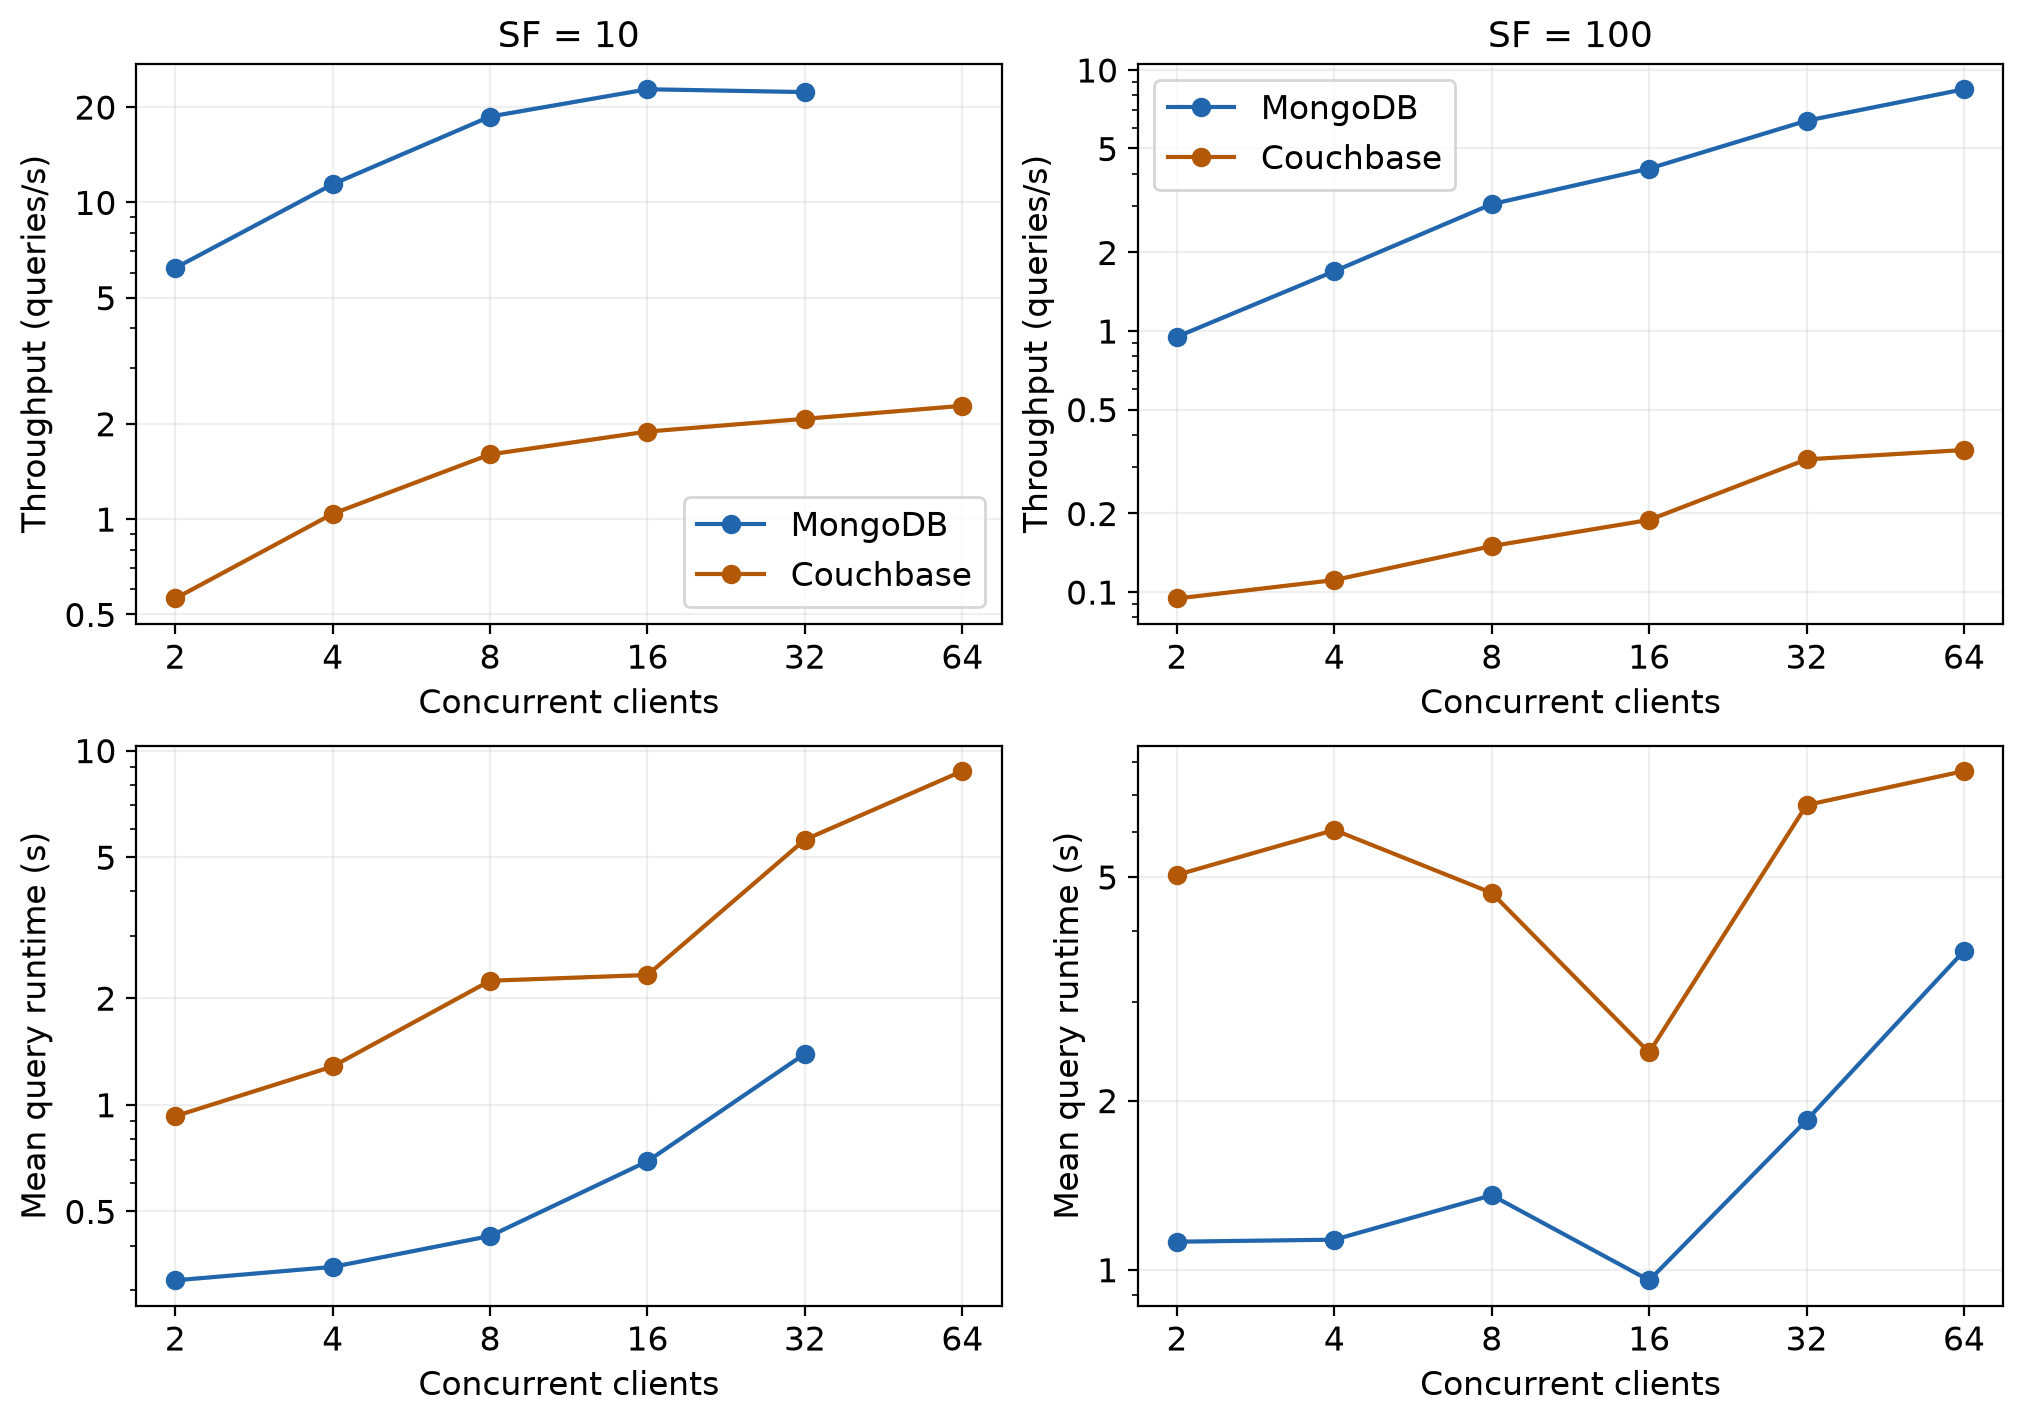

In [59]:
from json_bench.plotting import plot_client_scaling

runs = df.rename(
    columns={
        "param:backend": "backend",
        "param:clients": "clients",
        "param:scale_factor": "scale_factor",
        "metric:throughput_queries_per_second": "throughput_queries_per_second",
        "metric:mean_runtime_seconds": "mean_runtime_seconds",
    }
)

figure = plot_client_scaling(runs, dpi=200)
display(figure)

## Cohort details

Load saved outcome summaries and successful runtime samples for exactly the experiments selected above.


In [60]:
from json_bench.analysis import prepare_cohort
from json_bench.plotting import (
    plot_cohort_query_outcomes,
    plot_cohort_query_runtimes,
    plot_failure_heatmaps,
    plot_outcome_percentages,
)

experiments = {run_id: yr.get_experiment(run_id) for run_id in runs.index}
cohort = prepare_cohort(
    runs,
    summaries={run_id: exp.load_artifact("summary.json") for run_id, exp in experiments.items()},
    per_query={run_id: exp.load_artifact("per_query.json") for run_id, exp in experiments.items()},
)

## Normalized outcome bar charts

Bars show mean run-level outcome percentages for each backend, scale factor and client count.


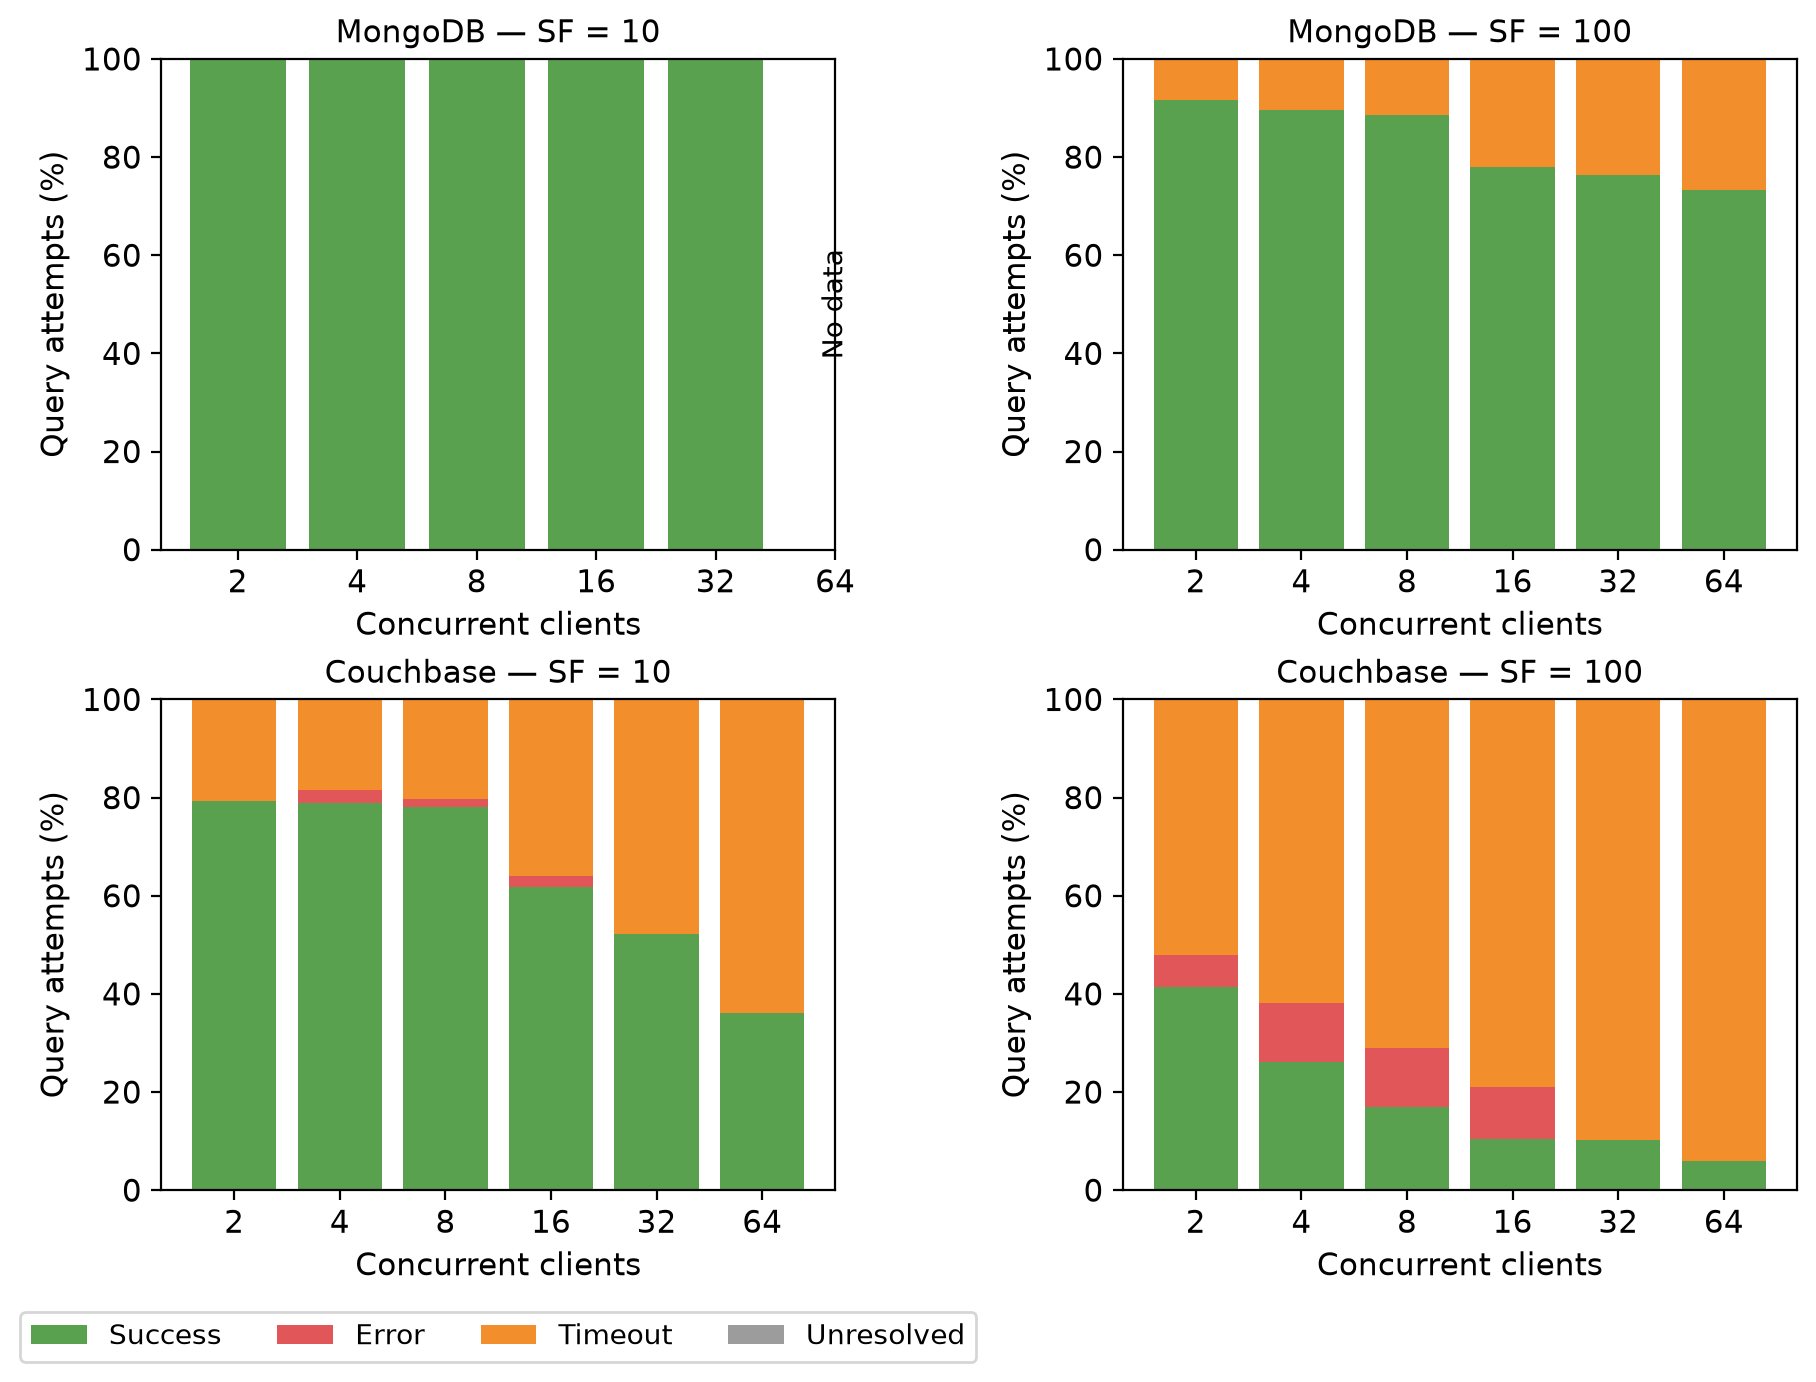

In [61]:
display(plot_outcome_percentages(cohort))

## Failure-rate heatmaps

Cells show mean run-level error plus timeout percentages; unresolved attempts remain in the denominator but are not counted as errors or timeouts.


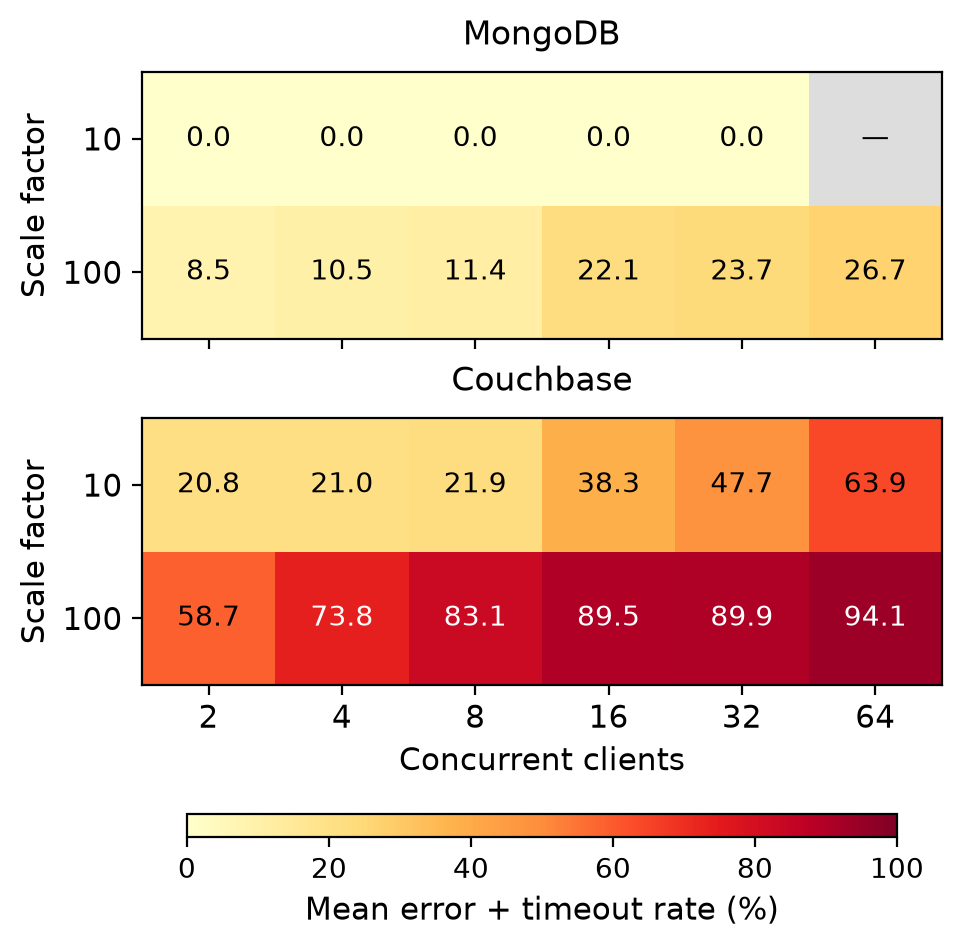

In [62]:
display(plot_failure_heatmaps(cohort))

## Query runtime box plots

Boxes pool successful runtimes across clients and repetitions, with medians, quartiles and 5th–95th percentile whiskers, separately per scale factor and overall.


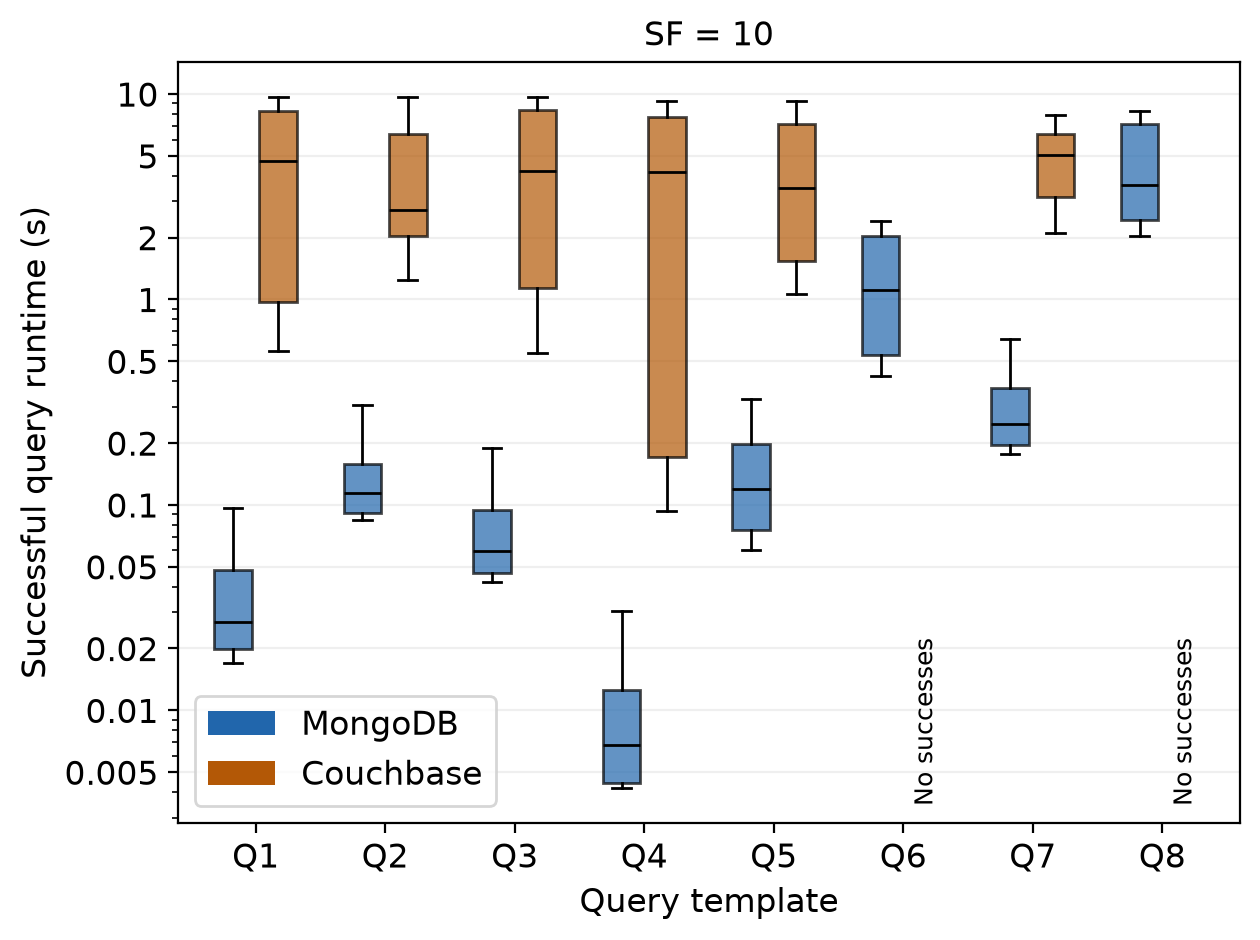

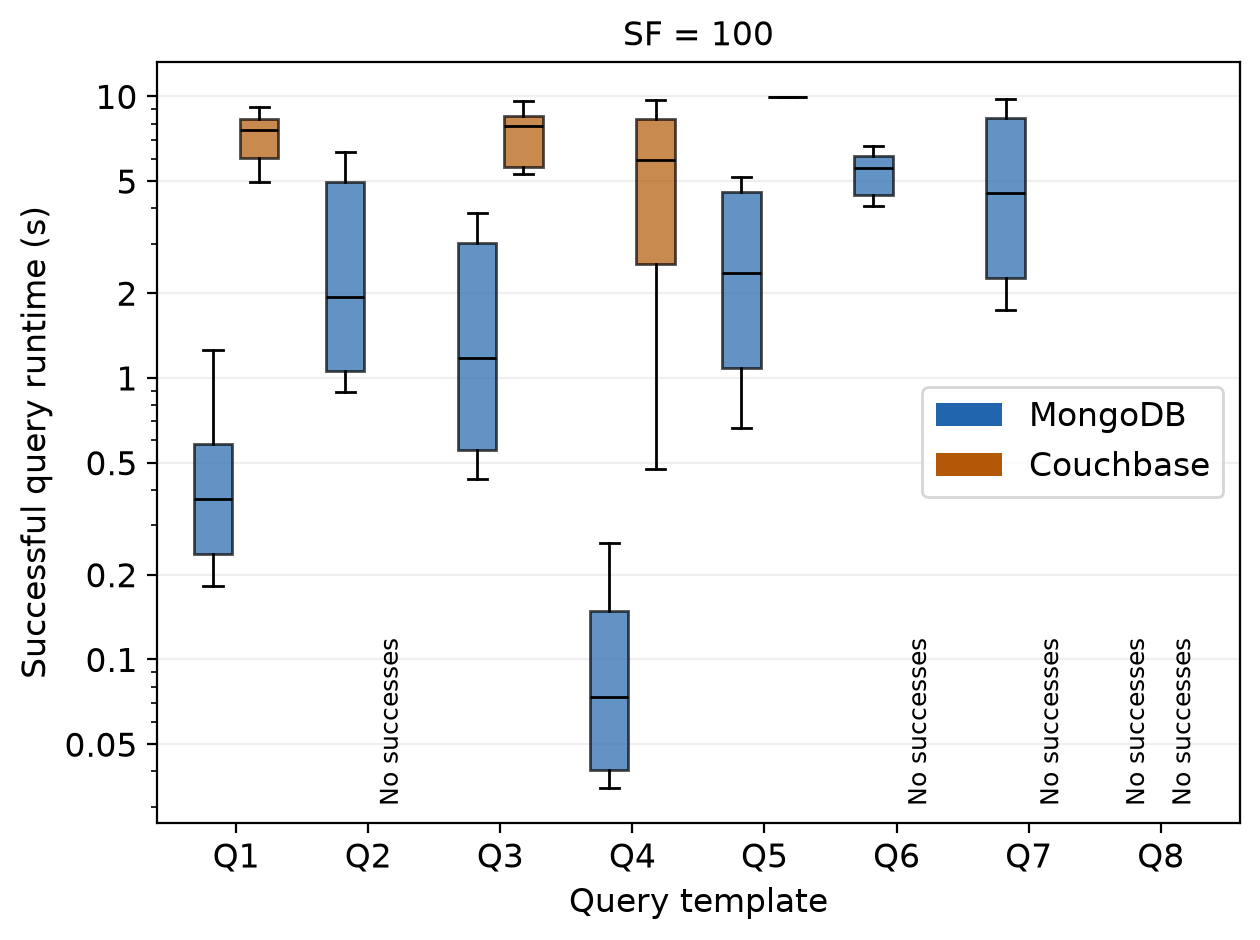

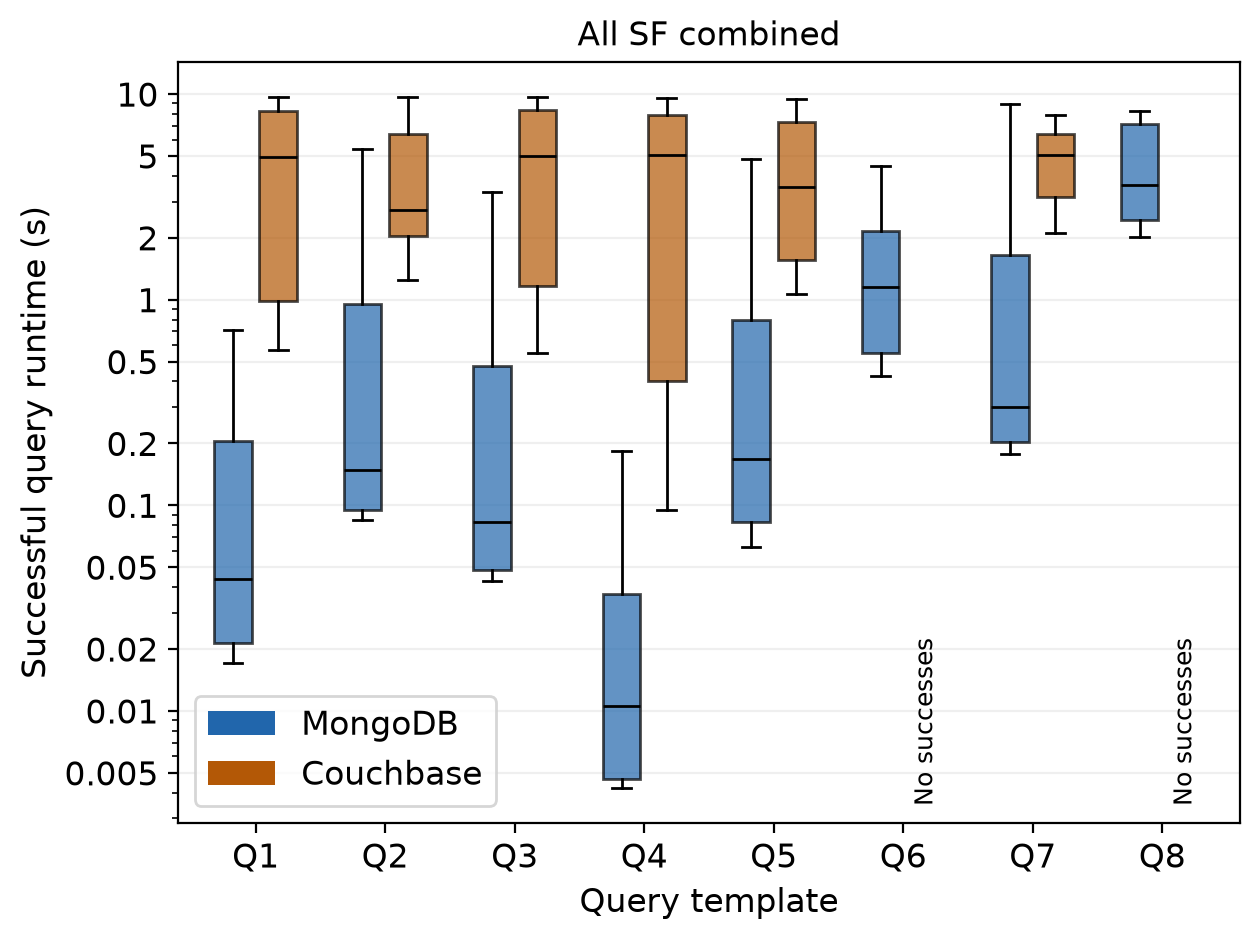

In [63]:
runtime_figures = plot_cohort_query_runtimes(cohort)
for figure in runtime_figures.values():
    display(figure)

## Query outcome counts

Stacked bars pool measurement outcome counts across clients and repetitions, separately per scale factor and overall.


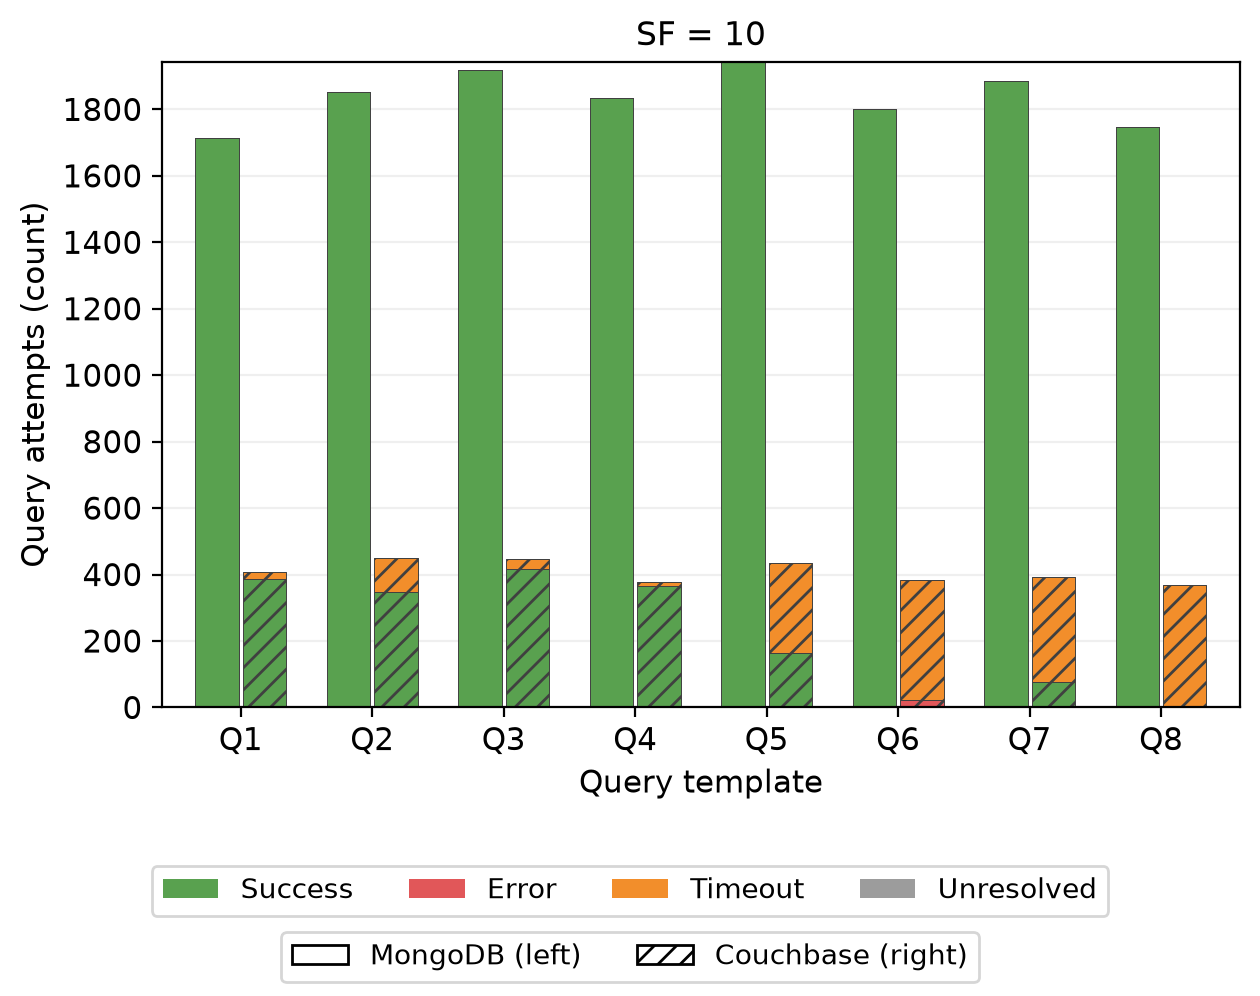

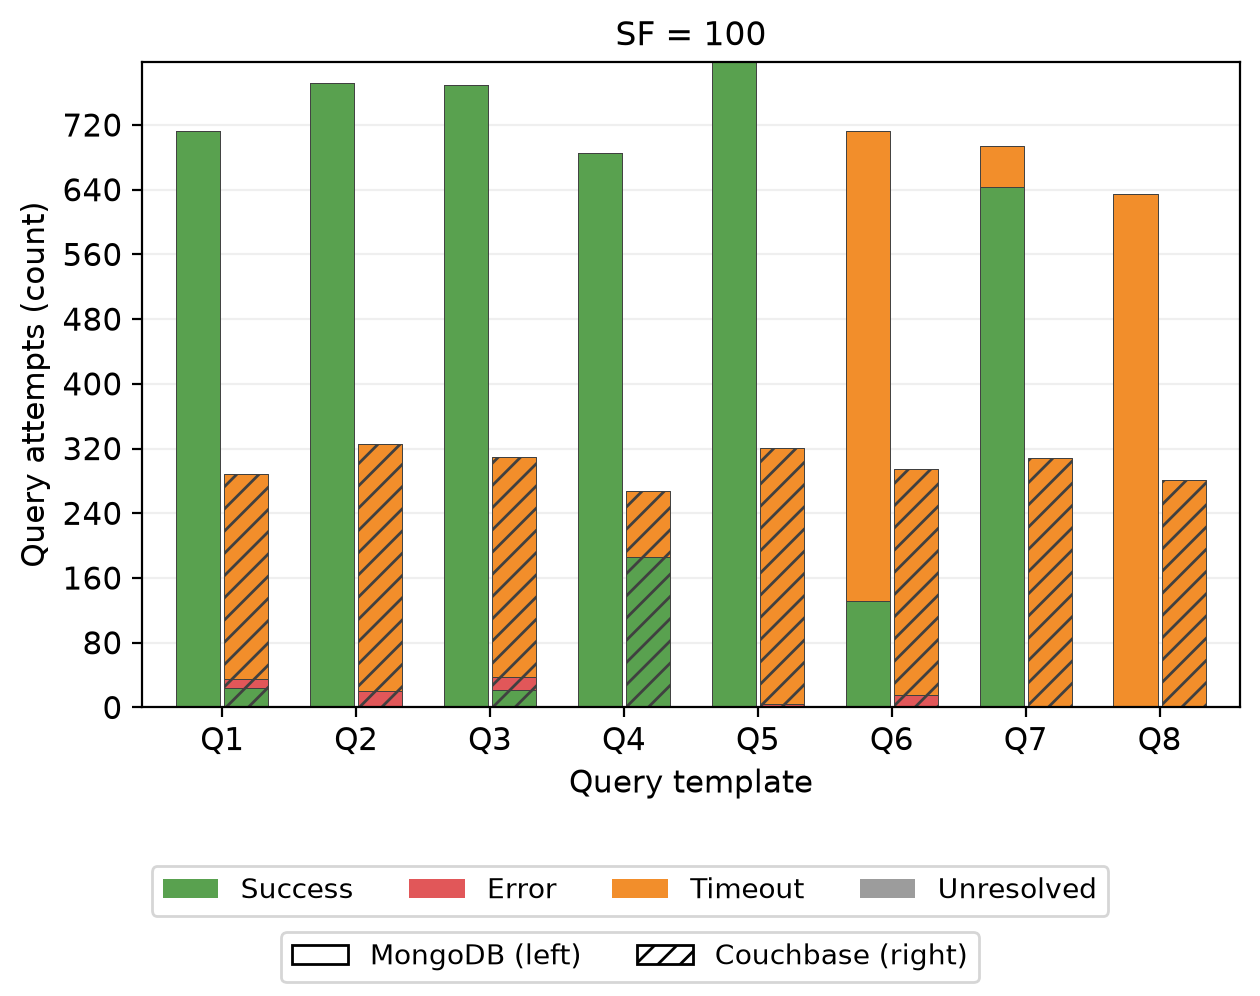

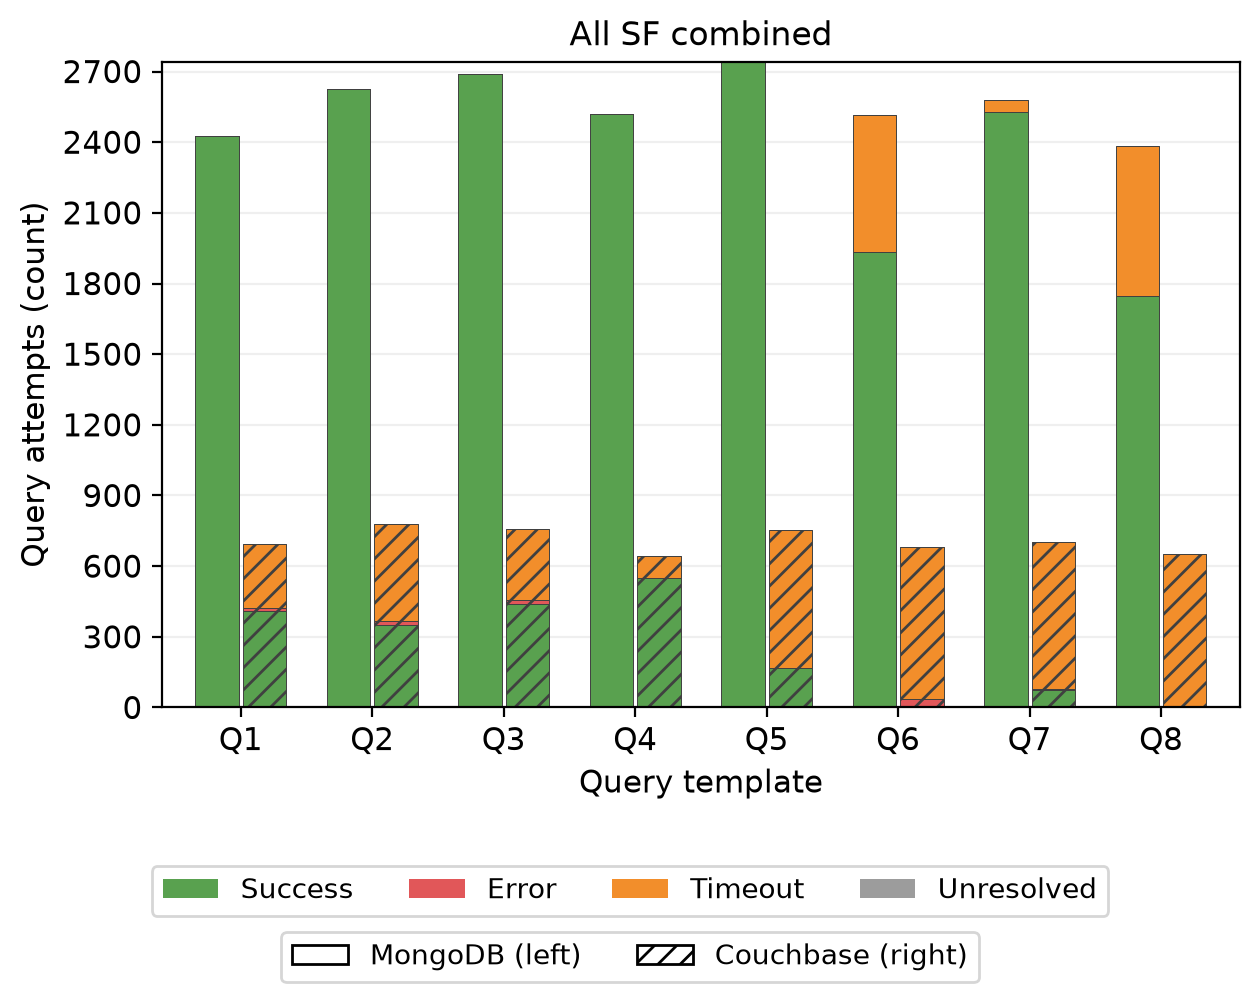

In [64]:
outcome_figures = plot_cohort_query_outcomes(cohort)
for figure in outcome_figures.values():
    display(figure)